# Lab 06 – Phân phối xác suất rời rạc và liên tục

## Nội Dung Bài Học

Bài lab trình bày các phân phối xác suất rời rạc Bernoulli, nhị thức, Poisson, hình học và các phân phối xác suất liên tục đều, chuẩn. Các ví dụ sử dụng `math`, `numpy` và `matplotlib` để tính xác suất và biểu diễn đồ thị.

## Phần I. Lý Thuyết

In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt


### 1. Phân phối Bernoulli

Phân phối Bernoulli là phân phối xác suất rời rạc của biến ngẫu nhiên chỉ nhận hai giá trị 0 hoặc 1. Giá trị 1 xuất hiện với xác suất thành công $p$; giá trị 0 xuất hiện với xác suất thất bại $q=1-p$. Ký hiệu:

$$X\sim\operatorname{Bernoulli}(p).$$

Hàm khối xác suất là

$$
P(X=x)=
\begin{cases}
p, & x=1,\\
1-p, & x=0,
\end{cases}
$$

hay

$$P(X=x)=p^x(1-p)^{1-x},\qquad x\in\{0,1\}.$$

Ví dụ, với một đồng xu cân bằng, quy ước mặt ngửa là $X=1$ và mặt sấp là $X=0$. Khi $p=0.5$, xác suất xuất hiện mặt ngửa bằng $0.5$.

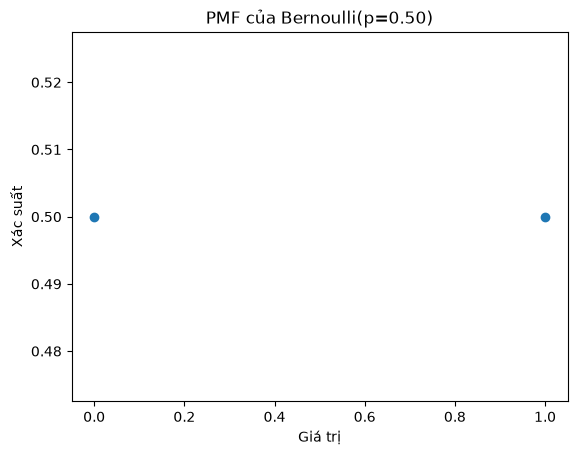

In [18]:
def pmf_bernoulli(p, x):
    return p**x * (1 - p)**(1 - x)


def plot_pmf_bernoulli(p):
    X = [0, 1]
    probabilities = [pmf_bernoulli(p, x) for x in X]
    plt.plot(X, probabilities, "o")
    plt.title(f"PMF của Bernoulli(p={p:.2f})")
    plt.xlabel("Giá trị")
    plt.ylabel("Xác suất")
    plt.show()
    plt.close()


plot_pmf_bernoulli(0.5)


### 2. Phân phối nhị thức

Phân phối nhị thức mô tả số lần thành công $k$ trong $n$ phép thử Bernoulli độc lập, khi xác suất thành công ở mỗi phép thử là $p$:

$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k},\qquad
k=0,1,\ldots,n,
$$

trong đó

$$\binom{n}{k}=\frac{n!}{k!(n-k)!}.$$

Ví dụ, khi tung đồng xu 15 lần với $p=0.5$, xác suất xuất hiện đúng 4 mặt ngửa là $\binom{15}{4}(0.5)^4(1-0.5)^{15-4}$.

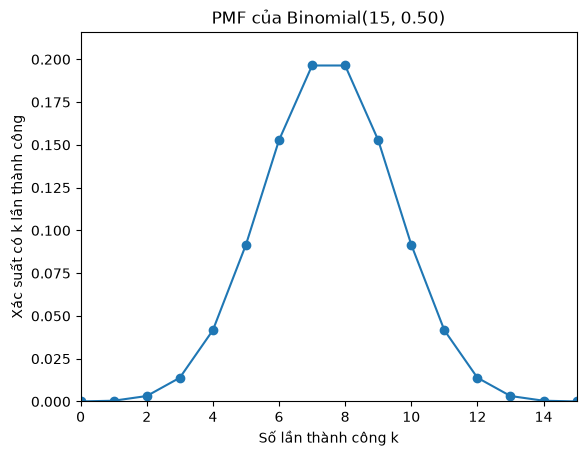

In [19]:
def pmf_binom(k, n, p):
    return math.comb(n, k) * p**k * (1 - p)**(n - k)


def plot_pmf_binom(n, p):
    K = list(range(n + 1))
    probabilities = [pmf_binom(k, n, p) for k in K]
    plt.plot(K, probabilities, "-o")
    plt.xlim(0, n)
    plt.ylim(0, 1.1 * max(probabilities))
    plt.title(f"PMF của Binomial({n}, {p:.2f})")
    plt.xlabel("Số lần thành công k")
    plt.ylabel("Xác suất có k lần thành công")
    plt.show()
    plt.close()


plot_pmf_binom(15, 0.5)


### 3. Phân phối Poisson

Phân phối Poisson là phân phối xác suất rời rạc mô tả số lần một sự kiện xảy ra trong một khoảng thời gian xác định. Số lần xảy ra trung bình trong khoảng thời gian đó được ký hiệu là $\lambda$. Hàm khối xác suất là

$$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!},\qquad k=0,1,2,\ldots$$

Ví dụ, một công ty tư vấn nhận trung bình 5 cuộc gọi mỗi phút. Với $\lambda=5$, xác suất nhận đúng 10 cuộc gọi trong một phút là

$$P(X=10)=\frac{5^{10}e^{-5}}{10!}\approx 0.018.$$

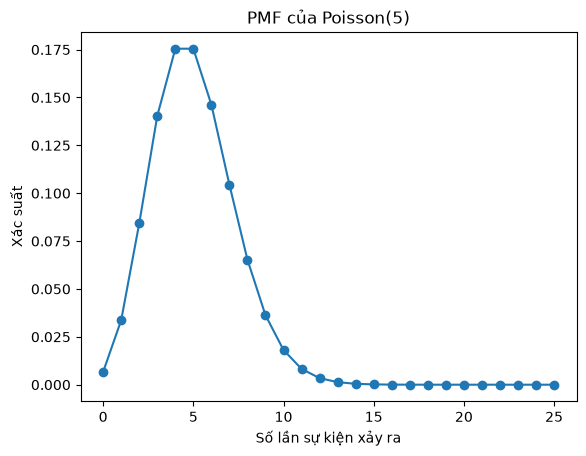

In [20]:
def pmf_poisson(k, lam):
    return lam**k * math.exp(-lam) / math.factorial(k)


def plot_pmf_poisson(n, lam):
    K = list(range(n + 1))
    probabilities = [pmf_poisson(k, lam) for k in K]
    plt.plot(K, probabilities, "-o")
    plt.title(f"PMF của Poisson({lam})")
    plt.xlabel("Số lần sự kiện xảy ra")
    plt.ylabel("Xác suất")
    plt.show()
    plt.close()


plot_pmf_poisson(25, 5)


### 4. Phân phối hình học

Phân phối hình học mô tả xác suất lần thành công đầu tiên xuất hiện ở phép thử Bernoulli thứ $x$. Hàm khối xác suất là

$$P(X=x)=p(1-p)^{x-1},\qquad x=1,2,3,\ldots$$

Ví dụ, xác suất ném vòng trúng đích ở mỗi lần là $p=0.3$. Xác suất lần đầu trúng ở lần ném thứ 5, tức trượt 4 lần trước đó, là

$$0.3(1-0.3)^{5-1}\approx 0.072.$$

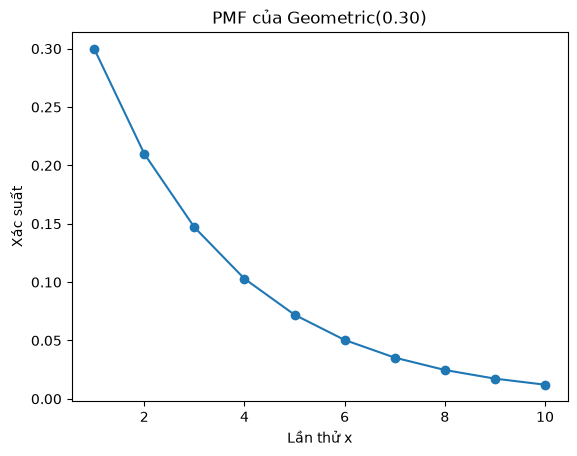

In [21]:
def pmf_geo(p, x):
    return p * (1 - p)**(x - 1)


def plot_pmf_geo(p, n):
    X = list(range(1, n + 1))
    probabilities = [pmf_geo(p, x) for x in X]
    plt.plot(X, probabilities, "-o")
    plt.title(f"PMF của Geometric({p:.2f})")
    plt.xlabel("Lần thử x")
    plt.ylabel("Xác suất")
    plt.show()
    plt.close()


plot_pmf_geo(0.3, 10)


### 5. Phân phối đều liên tục

Hàm `generator_data` tạo một dãy giá trị thực cách đều trên đoạn $[a,b]$. Trong ví dụ của tài liệu, biến $X$ gồm 100 giá trị liên tục trên đoạn $[4,6]$.

In [ ]:
def generator_data(a, b, size):
    step = (b - a) / (size - 1)
    result = []
    value = a
    while value < b:
        result.append(value)
        value += step
    if len(result) < size:
        result.append(b)
    return result


X = generator_data(4, 6, 100)
print(X)


[4, 4.02020202020202, 4.04040404040404, 4.06060606060606, 4.0808080808080796, 4.101010101010099, 4.121212121212119, 4.141414141414139, 4.161616161616159, 4.181818181818179, 4.202020202020199, 4.222222222222219, 4.242424242424239, 4.2626262626262585, 4.282828282828278, 4.303030303030298, 4.323232323232318, 4.343434343434338, 4.363636363636358, 4.383838383838378, 4.404040404040398, 4.424242424242418, 4.4444444444444375, 4.464646464646457, 4.484848484848477, 4.505050505050497, 4.525252525252517, 4.545454545454537, 4.565656565656557, 4.585858585858577, 4.606060606060597, 4.6262626262626165, 4.646464646464636, 4.666666666666656, 4.686868686868676, 4.707070707070696, 4.727272727272716, 4.747474747474736, 4.767676767676756, 4.787878787878776, 4.8080808080807955, 4.828282828282815, 4.848484848484835, 4.868686868686855, 4.888888888888875, 4.909090909090895, 4.929292929292915, 4.949494949494935, 4.969696969696955, 4.9898989898989745, 5.010101010100994, 5.030303030303014, 5.050505050505034, 5.070

Với phân phối đều liên tục trên $(a,b)$, mọi giá trị trong khoảng có cùng mật độ. Ký hiệu:

$$X\sim U(a,b).$$

Hàm mật độ xác suất là

$$f(x)=\frac{1}{b-a},\qquad x\in(a,b).$$

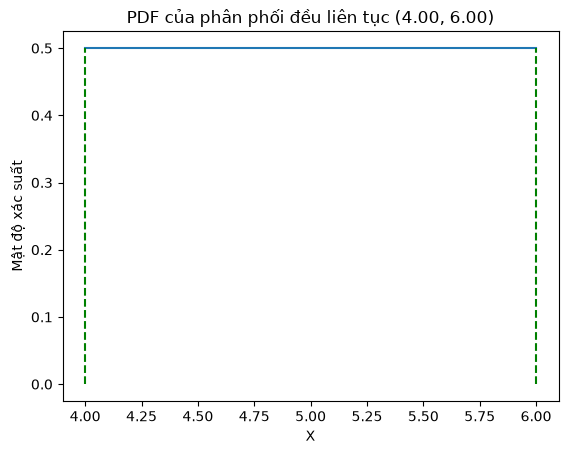

In [23]:
def pmf_uniform_cont(a, b):
    return 1 / (b - a)


def plot_pmf_uniform_cont(a, b):
    X = generator_data(a, b, 100)
    probabilities = [pmf_uniform_cont(a, b) for _ in X]
    plt.plot(X, probabilities, "-")
    plt.plot([a, a], [0, 1 / (b - a)], "g--")
    plt.plot([b, b], [0, 1 / (b - a)], "g--")
    plt.title(f"PDF của phân phối đều liên tục ({a:.2f}, {b:.2f})")
    plt.xlabel("X")
    plt.ylabel("Mật độ xác suất")
    plt.show()
    plt.close()


plot_pmf_uniform_cont(4, 6)


### 6. Phân phối chuẩn

Phân phối chuẩn, còn gọi là phân phối Gaussian, có kỳ vọng $\mu$ và độ lệch chuẩn $\sigma$. Hàm mật độ xác suất là

$$
f(x)=\frac{1}{\sqrt{2\pi}\sigma}
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).
$$

Hàm phân phối tích lũy là

$$
F(x)=\frac{1}{2}\left[1+\operatorname{erf}
\left(\frac{x-\mu}{\sigma\sqrt{2}}\right)\right].
$$

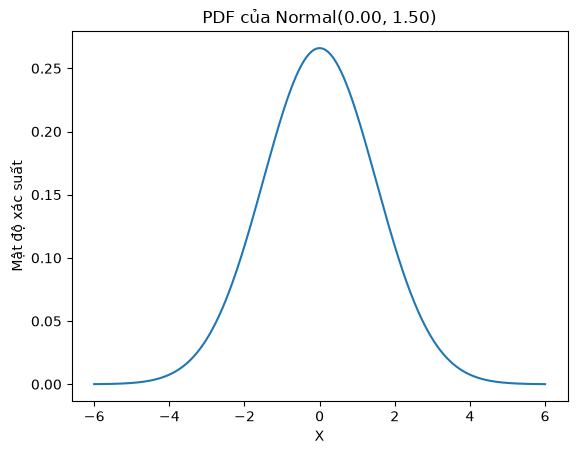

In [24]:
def pmf_normal(x, mu, sigma):
    coefficient = 1 / (math.sqrt(2 * math.pi) * sigma)
    exponent = -((x - mu)**2) / (2 * sigma**2)
    return coefficient * math.exp(exponent)


def cdf_normal(x, mu, sigma):
    return 0.5 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))


def plot_pmf_normal(mu, sigma):
    X = generator_data(mu - 4 * sigma, mu + 4 * sigma, 1000)
    probabilities = [pmf_normal(x, mu, sigma) for x in X]
    plt.plot(X, probabilities, "-")
    plt.title(f"PDF của Normal({mu:.2f}, {sigma:.2f})")
    plt.xlabel("X")
    plt.ylabel("Mật độ xác suất")
    plt.show()
    plt.close()


plot_pmf_normal(0, 1.5)


## Phần II. Bài tập thực hành

### Bài tập 1 – Số máy bị hỏng

Một nhà máy có 5 máy. Xác suất mỗi máy bị hỏng trong một ca là $0.1$.

a. Dùng hàm phân phối xác suất để tính xác suất có đúng 2 máy bị hỏng trong một ca. Kết quả tham khảo: $0.073$.

b. Gọi $X=\{0,1,2,3,4,5\}$ lần lượt là số máy bị hỏng trong một ca. Vẽ đồ thị biểu diễn mối quan hệ giữa $X$ và xác suất tương ứng.

In [25]:
# TODO - Hoàn thành Bài tập 1
def bai_tap_1():
    so_may = 5
    p = 0.1 
    a = pmf_binom(2,so_may,p)
    print(a)
bai_tap_1()

0.07290000000000002


### Bài tập 2 – Số cuộc gọi đến bưu điện

Một bưu điện nhận trung bình 3 cuộc gọi mỗi phút.

a. Dùng hàm phân phối xác suất để tính xác suất bưu điện nhận đúng 2 cuộc gọi trong một phút. Kết quả tham khảo: $0.224$.

b. Gọi $X=\{1,2,3,4,5\}$ lần lượt là số cuộc gọi đến bưu điện trong một phút. Vẽ đồ thị biểu diễn mối quan hệ giữa $X$ và xác suất tương ứng.

In [26]:
# TODO - Hoàn thành Bài tập 2
def bai_tap_2():
    
    pass


### Bài tập 3 – Lần bắn trúng đầu tiên

Mỗi người được cấp 10 viên đạn và bắn cho đến khi trúng mục tiêu lần đầu. Xác suất bắn trúng của mỗi viên là $40\%$.

a. Dùng hàm phân phối xác suất để tính xác suất người đó trúng mục tiêu ở lần bắn thứ 3. Kết quả tham khảo: $0.144$.

b. Gọi $X=\{1,2,3,4,5,6,7,8,9,10\}$ lần lượt là lần bắn mà người đó trúng mục tiêu lần đầu. Vẽ đồ thị biểu diễn mối quan hệ giữa $X$ và xác suất tương ứng.

In [27]:
# TODO - Hoàn thành Bài tập 3
def bai_tap_3():
    pass


### Bài tập 4 – Đồ thị hàm phân phối tích lũy chuẩn

Dùng hàm `cdf_normal` ở trên để vẽ đồ thị biểu diễn mối quan hệ giữa biến ngẫu nhiên $X$ tuân theo phân phối chuẩn với hai tham số $\mu$ và $\sigma$, và xác suất phân phối tích lũy tương ứng.

Trục hoành biểu diễn giá trị của $X$; trục tung biểu diễn xác suất tích lũy $F(x)$. Minh họa với $\mu=0$ và $\sigma=1.5$.

In [28]:
# TODO - Hoàn thành Bài tập 4
def bai_tap_4():
    pass


### Bài tập 5 – Thời gian sản xuất sản phẩm

Thời gian sản xuất một sản phẩm của phân xưởng A là biến ngẫu nhiên tuân theo phân phối chuẩn với $\mu=10$ và $\sigma=1$, đơn vị là phút.

Dùng các hàm trong bài để tính xác suất sản phẩm được hoàn thành trong khoảng từ 9 phút đến 12 phút. Kết quả tham khảo: $0.8185$.

In [29]:
# TODO - Hoàn thành Bài tập 5
def bai_tap_5():
    pass
